
# 1. Load the clustering features

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X_cluster_scaled_df = pd.read_csv('../data/processed/cluster_features.csv')

# 2.Elbow Method-find a good k

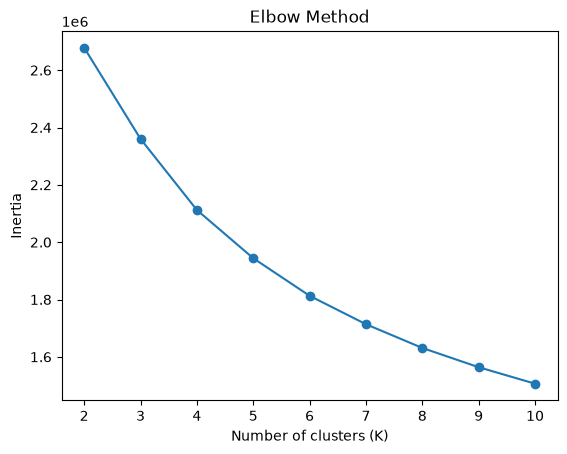

In [6]:
from sklearn.cluster import KMeans

inertias = []
K_range = range(2,11)

for K in K_range:
    km = KMeans(n_clusters=K,random_state=42,n_init=10)
    km.fit(X_cluster_scaled_df)
    inertias.append(km.inertia_)

plt.plot(K_range,inertias,marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.savefig('../reports/figures/elbow_plot.png')
plt.show()

# 3. Silhouette score — confirm k

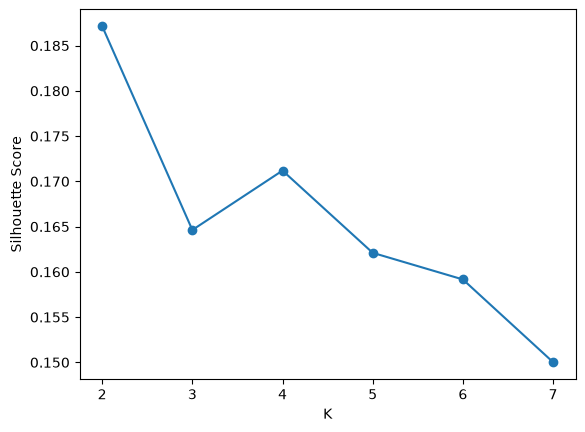

In [5]:
from sklearn.metrics import silhouette_score

sample = X_cluster_scaled_df.sample(20000, random_state=42)  #silhouette is expensive on full data

sil_scores = []
for K in range(2,8):
    km = KMeans(n_clusters=K, random_state=41,n_init=10)
    labels = km.fit_predict(sample)
    sil_scores.append(silhouette_score(sample, labels))

plt.plot(range(2,8),sil_scores, marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.savefig('../reports/figures/silhouette_plot.png')
plt.show()

# 4. Fit final KMeans with chosen k

In [7]:
k_final = 4    # replace with whatever the plots suggest
kmeans= KMeans(n_clusters=k_final,random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster_scaled_df)

df_clusters = X_cluster_scaled_df.copy()
df_clusters['cluster'] = cluster_labels

In [8]:
trait_scores = ['EXT_score','EST_score','AGR_score','CSN_score','OPN_score']

cluster_profiles = df_clusters.groupby('cluster')[trait_scores].mean()
print(cluster_profiles)

         EXT_score  EST_score  AGR_score  CSN_score  OPN_score
cluster                                                       
0        -0.663298  -0.167379  -1.336824   0.004498   0.416755
1         0.129447   0.720434   0.407138  -0.631716   0.516292
2         0.683701  -0.779092   0.581429   0.663034   0.288705
3        -0.504418   0.321727  -0.184328  -0.153987  -1.209048


# Step 5 — Bar chart of cluster profiles

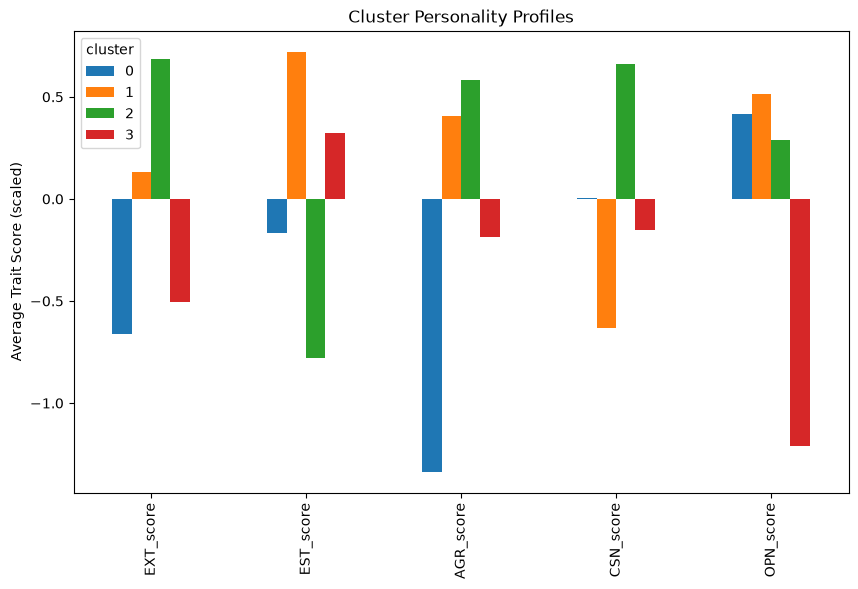

In [9]:
cluster_profiles.T.plot(kind='bar',figsize=(10,6))
plt.ylabel('Average Trait Score (scaled)')
plt.title("Cluster Personality Profiles")
plt.savefig('../reports/figures/cluster_profiles.png')
plt.show()

# Step 6 — PCA scatter

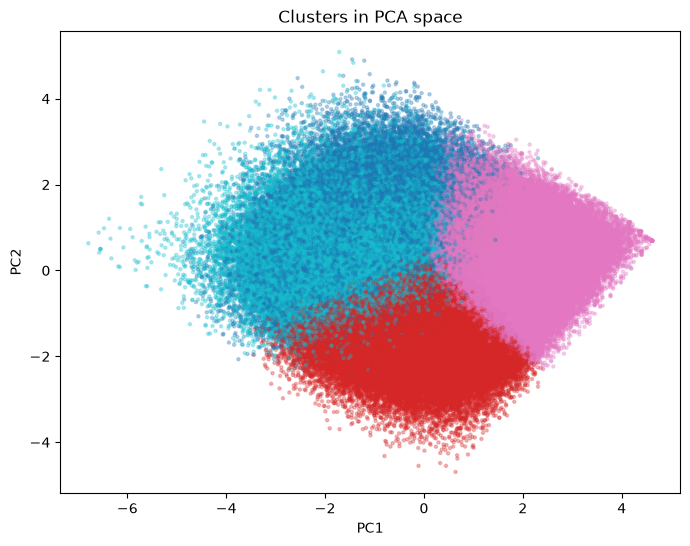

Explained varaince: [0.31900618 0.21042559]


In [10]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled_df)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0],X_pca[:,1],c=cluster_labels,cmap='tab10',alpha=0.3,s=5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters in PCA space')
plt.savefig('../reports/figures/pca_clusters.png')
plt.show()
print("Explained varaince:", pca.explained_variance_ratio_)

# Step 7 — Save

In [11]:
import joblib
joblib.dump(kmeans, '../models/kmeans_model.pkl')
df_clusters.to_csv('../data/processed/clustered_data.csv',index=False)

# Step 8 — Load the short-form data

In [4]:
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')

# Step 9 — Baseline: Linear Regression

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

lr=LinearRegression()
lr.fit(X_train, y_train)
pred_lr= lr.predict(X_test)

print("R^2:", r2_score(y_test,pred_lr, multioutput='raw_values'))
print("RMSE",mean_squared_error(y_test,pred_lr,multioutput='raw_values')**0.5)

R^2: [0.88732277 0.78787569 0.86347888 0.81124265 0.83149848]
RMSE [0.30503869 0.39618411 0.27243426 0.32192732 0.25502051]


# Step 10 — Stronger model: Random Forest

In [7]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50,max_depth=15,random_state=42,n_jobs=2)
rf.fit(X_train, y_train)
pred_rf= rf.predict(X_test)

print("R²:", r2_score(y_test, pred_rf, multioutput='raw_values'))
print("RMSE:", mean_squared_error(y_test, pred_rf, multioutput='raw_values')**0.5)

R²: [0.82728351 0.72458422 0.7658154  0.70627017 0.6871868 ]
RMSE: [0.3776624  0.45143605 0.35681325 0.40158726 0.34746873]


# Step 11 — Compare and save best model

In [8]:
import joblib
joblib.dump(rf, '../models/shortform_rf_model.pkl')  # or lr, whichever performs better

['../models/shortform_rf_model.pkl']